In [1]:
%matplotlib inline
import csv
import random
import time
from collections import Counter, deque
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from PIL import Image
from ultralytics import YOLO

In [2]:
DATA = Path("C:/Users/Krish/Downloads/archive/data")
WEIGHTS = "../weights/best.pt"
RUNS = Path("../runs")
RUNS.mkdir(exist_ok=True)

CLASSES = ["smoke", "fire"]
COLOURS = {"smoke": (160, 160, 160), "fire": (0, 0, 255)}

TRAIN = False
MODELS = ["yolov8n.pt"]
EPOCHS = 50

THRESHOLD = 0.5
WINDOW = 10
MIN_HITS = 5

with open(RUNS / "data.yaml", "w") as f:
    yaml.safe_dump({"path": str(DATA), "train": "train/images", "val": "val/images",
                    "test": "test/images", "names": {0: "smoke", 1: "fire"}}, f)

In [3]:
for split in ["train", "val", "test"]:
    images = [p for p in (DATA / split / "images").iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
    boxes = Counter()
    images_with = Counter()
    background = 0
    missing = 0

    for img in images:
        label = DATA / split / "labels" / (img.stem + ".txt")
        if not label.exists():
            missing += 1
            ids = []
        else:
            ids = [int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()]
        if not ids:
            background += 1
        boxes.update(ids)
        images_with.update(set(ids))

    print(f"[{split}] {len(images)} images, {background} background, {missing} missing labels")
    for c, name in enumerate(CLASSES):
        print(f"    {name:<6} {boxes[c]:>6} boxes in {images_with[c]:>6} images")

[train] 14122 images, 6458 background, 0 missing labels
    smoke    7794 boxes in   6894 images
    fire     9638 boxes in   3828 images
[val] 3099 images, 1375 background, 0 missing labels
    smoke    1756 boxes in   1550 images
    fire     2176 boxes in    879 images
[test] 4306 images, 2005 background, 0 missing labels
    smoke    2315 boxes in   2081 images
    fire     2878 boxes in   1115 images


In [4]:
CHECK_CORRUPT = False

if CHECK_CORRUPT:
    for split in ["train", "val", "test"]:
        bad = []
        for img in (DATA / split / "images").iterdir():
            try:
                with Image.open(img) as im:
                    im.load()
            except Exception:
                bad.append(img.name)
        print(split, len(bad), bad[:10])

In [5]:
if TRAIN:
    for m in MODELS:
        YOLO(m).train(
            data=str(RUNS / "data.yaml"),
            epochs=EPOCHS,
            patience=20,
            batch=16,
            imgsz=640,
            device=0,
            workers=8,
            seed=0,
            deterministic=True,
            project=str((RUNS / "train").resolve()),
            name=Path(m).stem,
            exist_ok=True,
        )

In [6]:
EVAL = RUNS / "evaluate"
EVAL.mkdir(exist_ok=True)

model = YOLO(WEIGHTS)
m = model.val(data=str(RUNS / "data.yaml"), split="test", imgsz=640, batch=16, device=0,
              project=str(EVAL.resolve()), name="val_test", exist_ok=True, verbose=False)

rows = [["all", m.box.mp, m.box.mr, m.box.map50, m.box.map]]
for i, c in enumerate(m.ap_class_index):
    rows.append([CLASSES[c], *m.box.class_result(i)])
box = pd.DataFrame(rows, columns=["class", "precision", "recall", "mAP50", "mAP50-95"]).round(3)
print(box.to_string(index=False))
print("speed (ms/img):", {k: round(v, 2) for k, v in m.speed.items()})

Ultralytics 8.4.180  Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.3±0.1 ms, read: 262.4±89.8 MB/s, size: 173.0 KB)
val: Scanning C:\Users\Krish\Downloads\archive\data\test\labels... 4306 images, 2005 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 4306/4306 2.9Kit/s 1.5s0.1s
val: C:\Users\Krish\Downloads\archive\data\test\images\WEB10769.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0296875]
val: C:\Users\Krish\Downloads\archive\data\test\images\WEB10775.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.015625]
val: C:\Users\Krish\Downloads\archive\data\test\images\WEB11598.jpg: ignoring corrupt image/label: non-normalized or out of bounds coordinates [1.0359375]
val: C:\Users\Krish\Downloads\archive\data\test\images\WEB11600.jpg: ignoring corrupt image/label: non-normalize

In [7]:
images = sorted(p for p in (DATA / "test" / "images").iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"])

gt = np.zeros((len(images), 2), dtype=bool)
for i, img in enumerate(images):
    label = DATA / "test" / "labels" / (img.stem + ".txt")
    if label.exists():
        for line in label.read_text().splitlines():
            if line.strip():
                gt[i, int(line.split()[0])] = True

if (EVAL / "predictions.npy").exists():
    conf = np.load(EVAL / "predictions.npy")
else:
    conf = np.zeros((len(images), 2), dtype=np.float32)
    for start in range(0, len(images), 256):
        batch = [str(p) for p in images[start:start + 256]]
        for i, r in enumerate(model.predict(batch, stream=True, conf=0.05, imgsz=640, device=0, verbose=False), start):
            for c, s in zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()):
                conf[i, c] = max(conf[i, c], s)
    np.save(EVAL / "predictions.npy", conf)

background = ~gt.any(axis=1)
print(len(images), "images,", background.sum(), "with no fire or smoke")

4306 images, 2005 with no fire or smoke


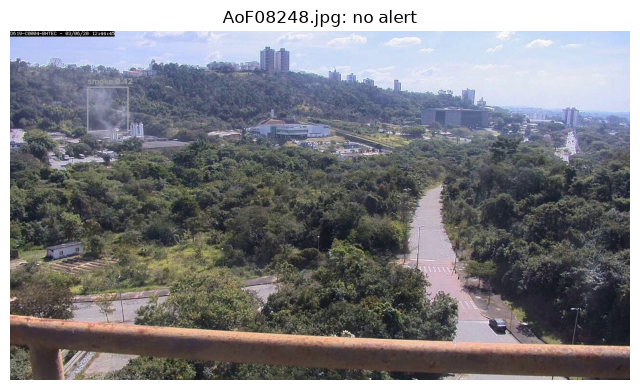

In [11]:
img_path = random.choice(images)
frame = cv2.imread(str(img_path))
r = model.predict(frame, verbose=False)[0]

found = set()
for (x1, y1, x2, y2), s, c in zip(r.boxes.xyxy.int().tolist(), r.boxes.conf.tolist(), r.boxes.cls.int().tolist()):
    name = CLASSES[c]
    cv2.rectangle(frame, (x1, y1), (x2, y2), COLOURS[name], 2)
    cv2.putText(frame, f"{name} {s:.2f}", (x1, max(y1 - 6, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, COLOURS[name], 2)
    if s >= THRESHOLD:
        found.add(name)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"{img_path.name}: " + ("ALERT " + ", ".join(sorted(found)) if found else "no alert"))
plt.axis("off")
plt.show()